In [1]:
# Imports
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
import openesm
import requests
from io import BytesIO
from IPython.display import display

from ingestion import load_dataset, storage
from preprocessing.standardization import standardize_dataset, get_response_columns, prepare_temporal_features
from preprocessing.schedule_reconstruction import reconstruct_schedule
from preprocessing.feature_engineering import engineer_features
from preprocessing.missingness import identify_nonresponse_rows
from utils.participant_analysis import analyze_participation, summarize_daily_activity, summarize_participant_daily_activity, analyze_daily_activity, analyze_participant_daily_activity
from utils.dataset_inspection import inspect_dataset
from utils.analysis_storage import save_analysis_table, save_visualization

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

In [2]:
# Configs
DATASET_ID = "0037"

In [3]:
df = load_dataset(DATASET_ID)

✓ Loading dataset 0037 version 1.0.0

ℹ For full reproducibility, use:
openesm.get_dataset("0037", metadata_version="2.0.0", version="1.0.0")


📊 OpenESM Dataset: 0037
   • Version: 1.0.0
   • Authors: Fisher et al. (2019)
   • Paper DOI: https://doi.org/10.31234/osf.io/e24v6
   • License: CC BY-NC 4.0
   • Data: A DataFrame with 52 participants and 128 maximum time points per 
participant

ℹ️  Use dataset.cite() for citation information.
ℹ️  Use dataset.notes() for additional information about the dataset.
ℹ️  Please ensure you follow the license terms for this dataset.




In [4]:
df.head()

,id,start_time,finish_time,cigs,angry,hungry,restless,down,bored,stressed,motivated_quit_smoking,want_quit,impulsive,sleep_difficulty,sleep_duration,day,craving_smoking,enjoy_last,trigger,irritable,concentrate,calm,happy,enthusiastic,nervous,tired,hurt_health,pos_expect,ashamed_smoking,agency,could_quit,delay_gratification,health_belief,comfortable,frustrated,pos_social,cig_predict,beep
0,2,2017-09-24T11:15:00Z,2017-09-24T11:19:00Z,0.0,35.0,58.0,70.0,60.0,21.0,63.0,37.0,62.0,43.0,62.0,6.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
1,2,2017-09-24T15:14:00Z,2017-09-24T15:18:00Z,3.0,37.0,68.0,NaN,41.0,33.0,65.0,53.0,29.0,65.0,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3
2,2,2017-09-24T19:05:00Z,2017-09-24T19:16:00Z,2.0,37.0,32.0,NaN,66.0,38.0,62.0,59.0,41.0,63.0,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4
3,2,2017-09-25T07:22:00Z,2017-09-25T08:04:00Z,5.0,67.0,61.0,66.0,76.0,24.0,84.0,57.0,64.0,68.0,70.0,4.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
4,2,2017-09-25T11:38:00Z,2017-09-25T12:32:00Z,3.0,41.0,59.0,NaN,76.0,39.0,73.0,39.0,62.0,64.0,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2


In [5]:
# df["date"] = pd.to_datetime(df["date"])

# df = df.sort_values(["id", "date"])

# df["date_gap"] = (
#     df.groupby("id")["date"]
#     .diff()
#     .dt.days
# )

# print(df["date_gap"].value_counts(dropna=False).sort_index())

In [6]:
with pd.option_context("display.max_rows", None):
    display(df.isna().sum().sort_values())

id                           0
beep                         0
day                         88
start_time                  88
down                       950
hungry                     950
bored                      950
finish_time                950
want_quit                  950
impulsive                  950
motivated_quit_smoking     950
stressed                   950
angry                      950
cigs                       952
restless                  1040
enjoy_last                1064
nervous                   1064
tired                     1064
trigger                   1064
irritable                 1064
concentrate               1064
calm                      1064
happy                     1064
enthusiastic              1064
ashamed_smoking           1064
agency                    1064
hurt_health               1064
pos_expect                1064
could_quit                1064
delay_gratification       1064
health_belief             1064
craving_smoking           1064
pos_soci

In [7]:
df.shape

(6392, 38)

In [8]:
for col in df.columns:
    print(f"{col}: {df[col].nunique()}")

id: 52
start_time: 6200
finish_time: 5373
cigs: 32
angry: 101
hungry: 101
restless: 100
down: 101
bored: 100
stressed: 101
motivated_quit_smoking: 101
want_quit: 101
impulsive: 100
sleep_difficulty: 98
sleep_duration: 31
day: 33
craving_smoking: 101
enjoy_last: 101
trigger: 100
irritable: 101
concentrate: 101
calm: 101
happy: 101
enthusiastic: 101
nervous: 100
tired: 101
hurt_health: 101
pos_expect: 101
ashamed_smoking: 101
agency: 99
could_quit: 101
delay_gratification: 101
health_belief: 97
comfortable: 101
frustrated: 101
pos_social: 101
cig_predict: 34
beep: 4


In [9]:
df.columns

Index(['id', 'start_time', 'finish_time', 'cigs', 'angry', 'hungry',
       'restless', 'down', 'bored', 'stressed', 'motivated_quit_smoking',
       'want_quit', 'impulsive', 'sleep_difficulty', 'sleep_duration', 'day',
       'craving_smoking', 'enjoy_last', 'trigger', 'irritable', 'concentrate',
       'calm', 'happy', 'enthusiastic', 'nervous', 'tired', 'hurt_health',
       'pos_expect', 'ashamed_smoking', 'agency', 'could_quit',
       'delay_gratification', 'health_belief', 'comfortable', 'frustrated',
       'pos_social', 'cig_predict', 'beep'],
      dtype='str')

In [10]:
df.head()

,id,start_time,finish_time,cigs,angry,hungry,restless,down,bored,stressed,motivated_quit_smoking,want_quit,impulsive,sleep_difficulty,sleep_duration,day,craving_smoking,enjoy_last,trigger,irritable,concentrate,calm,happy,enthusiastic,nervous,tired,hurt_health,pos_expect,ashamed_smoking,agency,could_quit,delay_gratification,health_belief,comfortable,frustrated,pos_social,cig_predict,beep
0,2,2017-09-24T11:15:00Z,2017-09-24T11:19:00Z,0.0,35.0,58.0,70.0,60.0,21.0,63.0,37.0,62.0,43.0,62.0,6.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
1,2,2017-09-24T15:14:00Z,2017-09-24T15:18:00Z,3.0,37.0,68.0,NaN,41.0,33.0,65.0,53.0,29.0,65.0,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3
2,2,2017-09-24T19:05:00Z,2017-09-24T19:16:00Z,2.0,37.0,32.0,NaN,66.0,38.0,62.0,59.0,41.0,63.0,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4
3,2,2017-09-25T07:22:00Z,2017-09-25T08:04:00Z,5.0,67.0,61.0,66.0,76.0,24.0,84.0,57.0,64.0,68.0,70.0,4.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
4,2,2017-09-25T11:38:00Z,2017-09-25T12:32:00Z,3.0,41.0,59.0,NaN,76.0,39.0,73.0,39.0,62.0,64.0,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2


In [11]:
df.dtypes

id                          int64
start_time                    str
finish_time                   str
cigs                      float64
angry                     float64
hungry                    float64
restless                  float64
down                      float64
bored                     float64
stressed                  float64
motivated_quit_smoking    float64
want_quit                 float64
impulsive                 float64
sleep_difficulty          float64
sleep_duration            float64
day                       float64
craving_smoking           float64
enjoy_last                float64
trigger                   float64
irritable                 float64
concentrate               float64
calm                      float64
happy                     float64
enthusiastic              float64
nervous                   float64
tired                     float64
hurt_health               float64
pos_expect                float64
ashamed_smoking           float64
agency        

In [12]:
df = standardize_dataset(df)

In [13]:
df.head()

,id,start_time,finish_time,cigs,angry,hungry,restless,down,bored,stressed,motivated_quit_smoking,want_quit,impulsive,sleep_difficulty,sleep_duration,day,craving_smoking,enjoy_last,trigger,irritable,concentrate,calm,happy,enthusiastic,nervous,tired,hurt_health,pos_expect,ashamed_smoking,agency,could_quit,delay_gratification,health_belief,comfortable,frustrated,pos_social,cig_predict,beep
0,2,2017-09-24T11:15:00Z,2017-09-24T11:19:00Z,0.0,35.0,58.0,70.0,60.0,21.0,63.0,37.0,62.0,43.0,62.0,6.0,1.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,2
1,2,2017-09-24T15:14:00Z,2017-09-24T15:18:00Z,3.0,37.0,68.0,<NA>,41.0,33.0,65.0,53.0,29.0,65.0,<NA>,<NA>,1.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,3
2,2,2017-09-24T19:05:00Z,2017-09-24T19:16:00Z,2.0,37.0,32.0,<NA>,66.0,38.0,62.0,59.0,41.0,63.0,<NA>,<NA>,1.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,4
3,2,2017-09-25T07:22:00Z,2017-09-25T08:04:00Z,5.0,67.0,61.0,66.0,76.0,24.0,84.0,57.0,64.0,68.0,70.0,4.0,2.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,1
4,2,2017-09-25T11:38:00Z,2017-09-25T12:32:00Z,3.0,41.0,59.0,<NA>,76.0,39.0,73.0,39.0,62.0,64.0,<NA>,<NA>,2.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,2


In [14]:
with pd.option_context("display.max_rows", None):
    display(df.isna().sum().sort_values())

id                           0
beep                         0
day                         88
start_time                  88
down                       950
hungry                     950
bored                      950
finish_time                950
want_quit                  950
impulsive                  950
motivated_quit_smoking     950
stressed                   950
angry                      950
cigs                       952
restless                  1040
enjoy_last                1064
nervous                   1064
tired                     1064
trigger                   1064
irritable                 1064
concentrate               1064
calm                      1064
happy                     1064
enthusiastic              1064
ashamed_smoking           1064
agency                    1064
hurt_health               1064
pos_expect                1064
could_quit                1064
delay_gratification       1064
health_belief             1064
craving_smoking           1064
pos_soci

In [15]:
df.shape

(6392, 38)

In [16]:
df.dtypes

id                          Int64
start_time                 string
finish_time                string
cigs                      Float64
angry                     Float64
hungry                    Float64
restless                  Float64
down                      Float64
bored                     Float64
stressed                  Float64
motivated_quit_smoking    Float64
want_quit                 Float64
impulsive                 Float64
sleep_difficulty          Float64
sleep_duration            Float64
day                       Float64
craving_smoking           Float64
enjoy_last                Float64
trigger                   Float64
irritable                 Float64
concentrate               Float64
calm                      Float64
happy                     Float64
enthusiastic              Float64
nervous                   Float64
tired                     Float64
hurt_health               Float64
pos_expect                Float64
ashamed_smoking           Float64
agency        

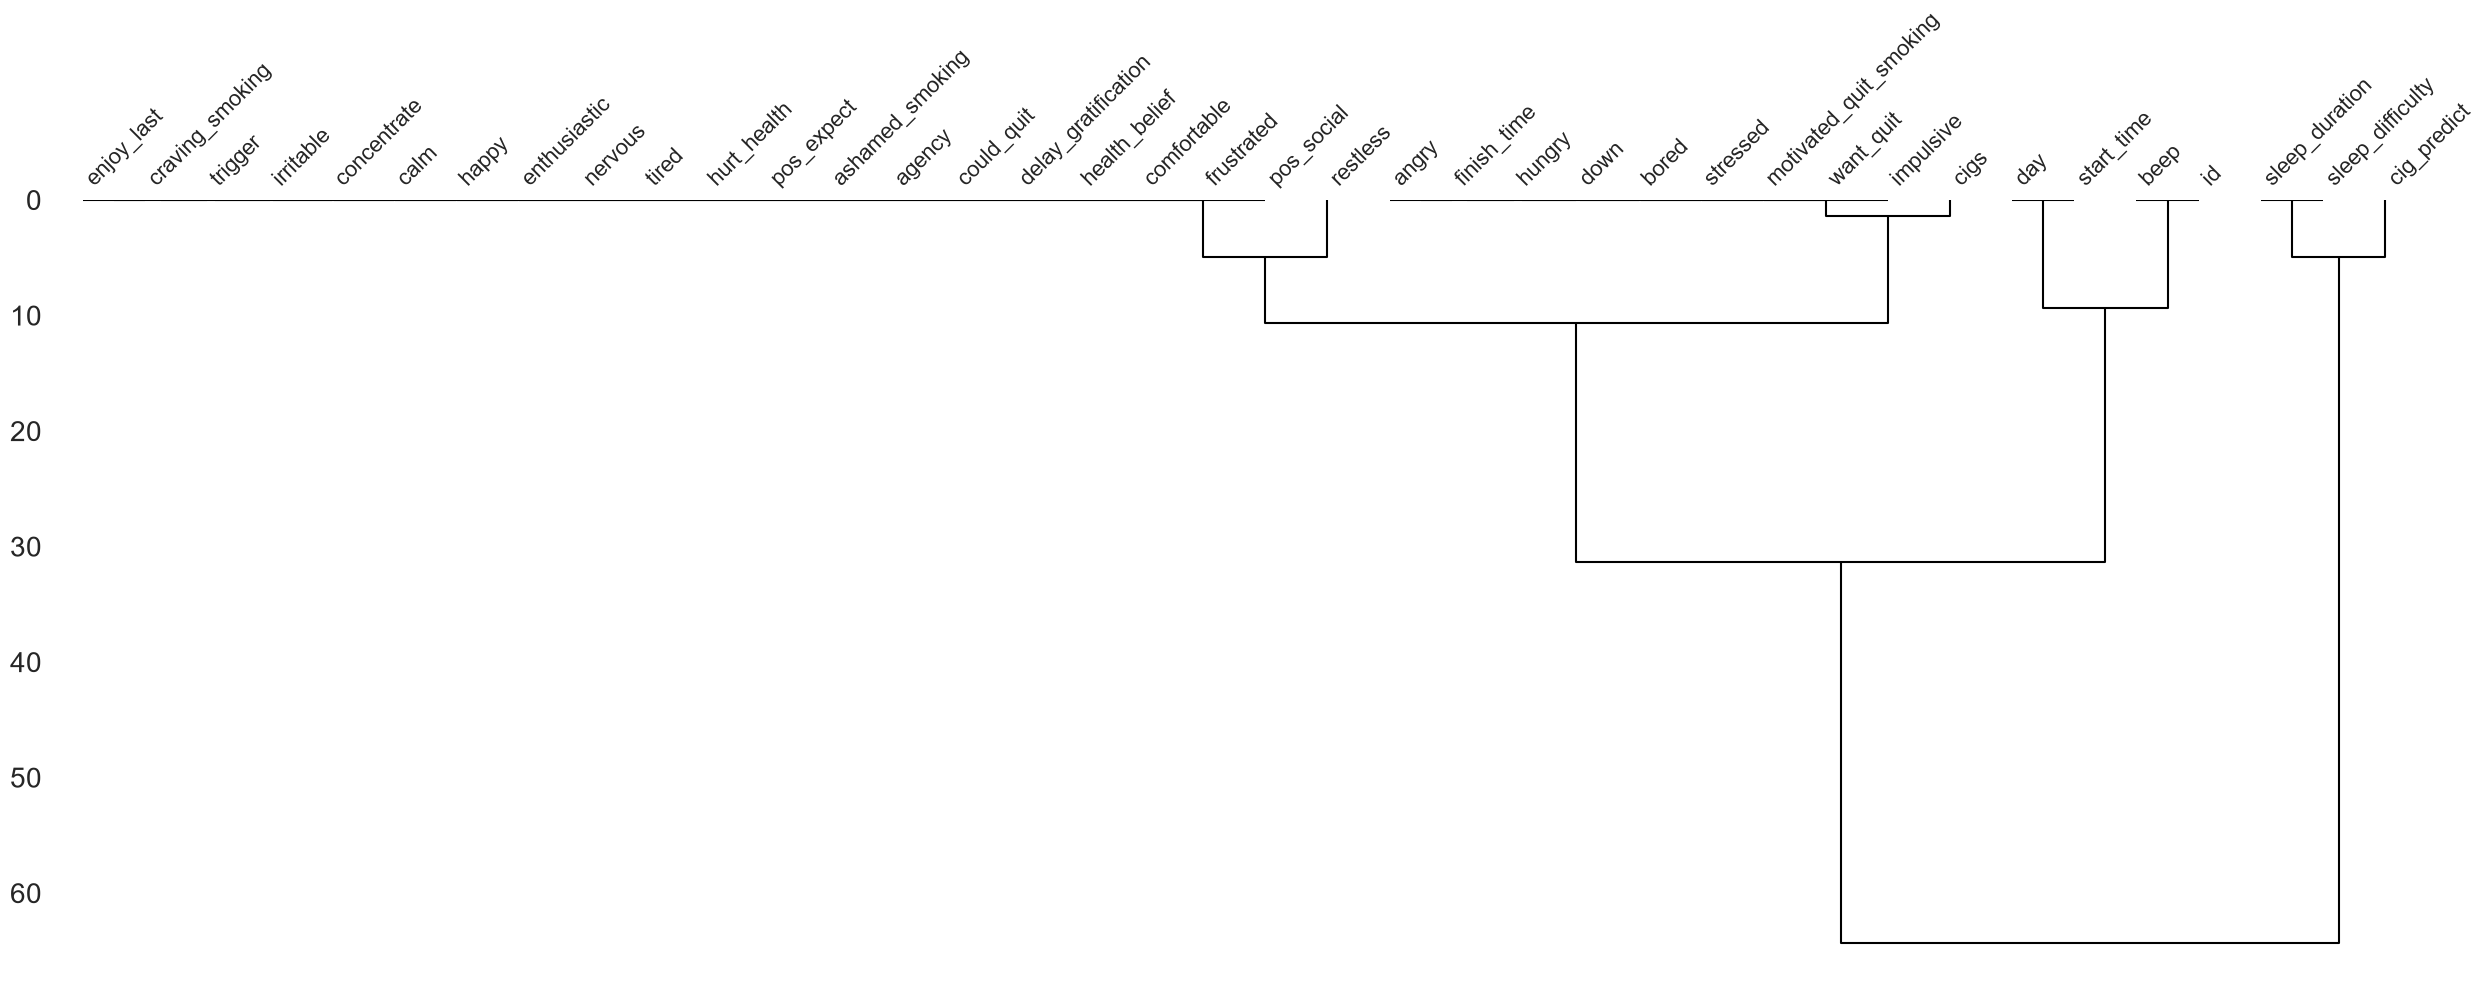

In [17]:
ax = msno.dendrogram(df=df)
plt.tight_layout()
plt.show()

In [18]:
tick_positions = ax.get_xticks()
tick_labels = [tick.get_text() for tick in ax.get_xticklabels()]

for collection_idx, collection in enumerate(ax.collections):
    if not hasattr(collection, "get_segments"):
        continue

    print(f"\nCOLLECTION {collection_idx}")

    for segment_idx, segment in enumerate(collection.get_segments()):
        print(f"\n  Segment {segment_idx}:")

        for x, y in segment:
            nearest_tick_idx = abs(tick_positions - x).argmin()
            label = tick_labels[nearest_tick_idx]

            print(f"    x={x:8.4f} ({label:<30}) y={y:.4f}")


COLLECTION 0

  Segment 0:
    x=  5.0000 (enjoy_last                    ) y=0.0000
    x=  5.0000 (enjoy_last                    ) y=0.0000
    x= 15.0000 (craving_smoking               ) y=0.0000
    x= 15.0000 (craving_smoking               ) y=0.0000

  Segment 1:
    x= 10.0000 (enjoy_last                    ) y=0.0000
    x= 10.0000 (enjoy_last                    ) y=0.0000
    x= 25.0000 (trigger                       ) y=0.0000
    x= 25.0000 (trigger                       ) y=0.0000

  Segment 2:
    x= 17.5000 (craving_smoking               ) y=0.0000
    x= 17.5000 (craving_smoking               ) y=0.0000
    x= 35.0000 (irritable                     ) y=0.0000
    x= 35.0000 (irritable                     ) y=0.0000

  Segment 3:
    x= 26.2500 (trigger                       ) y=0.0000
    x= 26.2500 (trigger                       ) y=0.0000
    x= 45.0000 (concentrate                   ) y=0.0000
    x= 45.0000 (concentrate                   ) y=0.0000

  Segment 4:
    

In [19]:
for column in df.columns:
    if column == "id":
        continue

    print(f"{column}: {df[column].dropna().unique().tolist()}")

start_time: ['2017-09-24T11:15:00Z', '2017-09-24T15:14:00Z', '2017-09-24T19:05:00Z', '2017-09-25T07:22:00Z', '2017-09-25T11:38:00Z', '2017-09-25T15:24:00Z', '2017-09-25T19:36:00Z', '2017-09-26T07:13:00Z', '2017-09-26T11:06:00Z', '2017-09-26T15:07:00Z', '2017-09-26T19:29:00Z', '2017-09-27T07:11:00Z', '2017-09-27T11:57:00Z', '2017-09-27T15:56:00Z', '2017-09-27T19:35:00Z', '2017-09-28T07:23:00Z', '2017-09-28T11:27:00Z', '2017-09-28T15:38:00Z', '2017-09-28T19:05:00Z', '2017-09-29T07:32:00Z', '2017-09-29T11:44:00Z', '2017-09-29T15:09:00Z', '2017-09-29T19:38:00Z', '2017-09-30T07:22:00Z', '2017-09-30T11:20:00Z', '2017-09-30T15:20:00Z', '2017-09-30T19:51:00Z', '2017-10-01T07:37:00Z', '2017-10-01T11:47:00Z', '2017-10-01T15:34:00Z', '2017-10-01T19:09:00Z', '2017-10-02T07:18:00Z', '2017-10-02T11:16:00Z', '2017-10-02T15:39:00Z', '2017-10-02T19:58:00Z', '2017-10-03T07:49:00Z', '2017-10-03T11:29:00Z', '2017-10-03T15:58:00Z', '2017-10-03T19:11:00Z', '2017-10-04T07:26:00Z', '2017-10-04T11:19:00Z', '20

In [20]:
df["id"].nunique()

52

In [21]:
df["beep"].value_counts()

beep
2    1598
3    1598
4    1598
1    1598
Name: count, dtype: Int64

In [22]:
df["beep"].unique()

<IntegerArray>
[2, 3, 4, 1]
Length: 4, dtype: Int64

In [23]:
for column in df.columns:
    if column == "id":
        continue

    print(f"{column}: {df[column].nunique()}")

start_time: 6200
finish_time: 5373
cigs: 32
angry: 101
hungry: 101
restless: 100
down: 101
bored: 100
stressed: 101
motivated_quit_smoking: 101
want_quit: 101
impulsive: 100
sleep_difficulty: 98
sleep_duration: 31
day: 33
craving_smoking: 101
enjoy_last: 101
trigger: 100
irritable: 101
concentrate: 101
calm: 101
happy: 101
enthusiastic: 101
nervous: 100
tired: 101
hurt_health: 101
pos_expect: 101
ashamed_smoking: 101
agency: 99
could_quit: 101
delay_gratification: 101
health_belief: 97
comfortable: 101
frustrated: 101
pos_social: 101
cig_predict: 34
beep: 4


In [24]:
inspection = inspect_dataset(
    df=df,
    dataset_id=DATASET_ID,
)

In [25]:
display(
    pd.DataFrame(
        inspection["metadata"].items(),
        columns=["Field", "Value"],
    )
)

,Field,Value
0,dataset_id,0037
1,first_author,Fisher
2,year,2019
3,n_participants,52
4,n_time_points,128
5,n_days,34
6,n_beeps_per_day,4
7,passive_data_available,no
8,cross_sectional_available,no
9,sampling_scheme,4x/day random schedule


In [26]:
response_cols = get_response_columns(df)

print(f"Response columns: {len(response_cols)}")
print(response_cols)

Response columns: 34
['finish_time', 'cigs', 'angry', 'hungry', 'restless', 'down', 'bored', 'stressed', 'motivated_quit_smoking', 'want_quit', 'impulsive', 'sleep_difficulty', 'sleep_duration', 'craving_smoking', 'enjoy_last', 'trigger', 'irritable', 'concentrate', 'calm', 'happy', 'enthusiastic', 'nervous', 'tired', 'hurt_health', 'pos_expect', 'ashamed_smoking', 'agency', 'could_quit', 'delay_gratification', 'health_belief', 'comfortable', 'frustrated', 'pos_social', 'cig_predict']


In [27]:
metadata = inspection["metadata"]

EXPECTED_DAYS = list(range(1, int(metadata["n_days"]) + 1))
EXPECTED_BEEPS = list(range(1, int(metadata["n_beeps_per_day"]) + 1))
FINAL_STUDY_DAY = max(EXPECTED_DAYS)

In [28]:
reconstruction = reconstruct_schedule(
    df=df,
    response_cols=response_cols,
    expected_days=EXPECTED_DAYS,
    expected_beeps=EXPECTED_BEEPS,
)

df_reconstructed = reconstruction["reconstructed_df"]
schedule_check = reconstruction["schedule_check"]
summary = reconstruction["summary"]

In [29]:
df_reconstructed.head()

,id,start_time,finish_time,cigs,angry,hungry,restless,down,bored,stressed,motivated_quit_smoking,want_quit,impulsive,sleep_difficulty,sleep_duration,day,craving_smoking,enjoy_last,trigger,irritable,concentrate,calm,happy,enthusiastic,nervous,tired,hurt_health,pos_expect,ashamed_smoking,agency,could_quit,delay_gratification,health_belief,comfortable,frustrated,pos_social,cig_predict,beep,is_duplicate,is_unexpected,is_invalid,is_reconstructed,is_nonresponse,is_partial_response,response_status,schedule_status
0,2,2017-09-24T11:15:00Z,2017-09-24T11:19:00Z,0.0,35.0,58.0,70.0,60.0,21.0,63.0,37.0,62.0,43.0,62.0,6.0,1.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,2,False,False,False,False,False,True,partial,valid
1,2,2017-09-24T15:14:00Z,2017-09-24T15:18:00Z,3.0,37.0,68.0,<NA>,41.0,33.0,65.0,53.0,29.0,65.0,<NA>,<NA>,1.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,3,False,False,False,False,False,True,partial,valid
2,2,2017-09-24T19:05:00Z,2017-09-24T19:16:00Z,2.0,37.0,32.0,<NA>,66.0,38.0,62.0,59.0,41.0,63.0,<NA>,<NA>,1.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,4,False,False,False,False,False,True,partial,valid
3,2,2017-09-25T07:22:00Z,2017-09-25T08:04:00Z,5.0,67.0,61.0,66.0,76.0,24.0,84.0,57.0,64.0,68.0,70.0,4.0,2.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,1,False,False,False,False,False,True,partial,valid
4,2,2017-09-25T11:38:00Z,2017-09-25T12:32:00Z,3.0,41.0,59.0,<NA>,76.0,39.0,73.0,39.0,62.0,64.0,<NA>,<NA>,2.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,2,False,False,False,False,False,True,partial,valid


In [30]:
df_reconstructed.shape

(7160, 46)

In [31]:
for column in df_reconstructed.columns:
    if column == "id":
        continue

    print(
        f"{column}: "
        f"{df_reconstructed[column].dropna().unique().tolist()}"
    )

start_time: ['2017-09-24T11:15:00Z', '2017-09-24T15:14:00Z', '2017-09-24T19:05:00Z', '2017-09-25T07:22:00Z', '2017-09-25T11:38:00Z', '2017-09-25T15:24:00Z', '2017-09-25T19:36:00Z', '2017-09-26T07:13:00Z', '2017-09-26T11:06:00Z', '2017-09-26T15:07:00Z', '2017-09-26T19:29:00Z', '2017-09-27T07:11:00Z', '2017-09-27T11:57:00Z', '2017-09-27T15:56:00Z', '2017-09-27T19:35:00Z', '2017-09-28T07:23:00Z', '2017-09-28T11:27:00Z', '2017-09-28T15:38:00Z', '2017-09-28T19:05:00Z', '2017-09-29T07:32:00Z', '2017-09-29T11:44:00Z', '2017-09-29T15:09:00Z', '2017-09-29T19:38:00Z', '2017-09-30T07:22:00Z', '2017-09-30T11:20:00Z', '2017-09-30T15:20:00Z', '2017-09-30T19:51:00Z', '2017-10-01T07:37:00Z', '2017-10-01T11:47:00Z', '2017-10-01T15:34:00Z', '2017-10-01T19:09:00Z', '2017-10-02T07:18:00Z', '2017-10-02T11:16:00Z', '2017-10-02T15:39:00Z', '2017-10-02T19:58:00Z', '2017-10-03T07:49:00Z', '2017-10-03T11:29:00Z', '2017-10-03T15:58:00Z', '2017-10-03T19:11:00Z', '2017-10-04T07:26:00Z', '2017-10-04T11:19:00Z', '20

In [32]:
for column in df_reconstructed.columns:
    if column == "id":
        continue

    print(
        f"{column}: "
        f"{df_reconstructed[column].dropna().unique().tolist()}"
    )

start_time: ['2017-09-24T11:15:00Z', '2017-09-24T15:14:00Z', '2017-09-24T19:05:00Z', '2017-09-25T07:22:00Z', '2017-09-25T11:38:00Z', '2017-09-25T15:24:00Z', '2017-09-25T19:36:00Z', '2017-09-26T07:13:00Z', '2017-09-26T11:06:00Z', '2017-09-26T15:07:00Z', '2017-09-26T19:29:00Z', '2017-09-27T07:11:00Z', '2017-09-27T11:57:00Z', '2017-09-27T15:56:00Z', '2017-09-27T19:35:00Z', '2017-09-28T07:23:00Z', '2017-09-28T11:27:00Z', '2017-09-28T15:38:00Z', '2017-09-28T19:05:00Z', '2017-09-29T07:32:00Z', '2017-09-29T11:44:00Z', '2017-09-29T15:09:00Z', '2017-09-29T19:38:00Z', '2017-09-30T07:22:00Z', '2017-09-30T11:20:00Z', '2017-09-30T15:20:00Z', '2017-09-30T19:51:00Z', '2017-10-01T07:37:00Z', '2017-10-01T11:47:00Z', '2017-10-01T15:34:00Z', '2017-10-01T19:09:00Z', '2017-10-02T07:18:00Z', '2017-10-02T11:16:00Z', '2017-10-02T15:39:00Z', '2017-10-02T19:58:00Z', '2017-10-03T07:49:00Z', '2017-10-03T11:29:00Z', '2017-10-03T15:58:00Z', '2017-10-03T19:11:00Z', '2017-10-04T07:26:00Z', '2017-10-04T11:19:00Z', '20

pos_expect: [22.0, 21.0, 0.0, 14.0, 78.0, 81.0, 28.0, 70.0, 8.0, 100.0, 15.0, 10.0, 6.0, 85.0, 16.0, 2.0, 17.0, 79.0, 20.0, 75.0, 26.0, 11.0, 74.0, 12.0, 88.0, 73.0, 7.0, 71.0, 68.0, 87.0, 67.0, 9.0, 4.0, 96.0, 91.0, 29.0, 80.0, 3.0, 1.0, 13.0, 66.0, 19.0, 55.0, 56.0, 82.0, 60.0, 76.0, 72.0, 32.0, 50.0, 77.0, 24.0, 59.0, 69.0, 65.0, 31.0, 37.0, 36.0, 43.0, 61.0, 34.0, 33.0, 44.0, 58.0, 62.0, 23.0, 30.0, 25.0, 27.0, 18.0, 38.0, 57.0, 41.0, 54.0, 39.0, 63.0, 64.0, 51.0, 35.0, 40.0, 95.0, 52.0, 89.0, 90.0, 84.0, 86.0, 45.0, 42.0, 94.0, 47.0, 83.0, 5.0, 99.0, 93.0, 98.0, 92.0, 53.0, 49.0, 48.0, 97.0, 46.0]
ashamed_smoking: [14.0, 0.0, 17.0, 10.0, 5.0, 13.0, 21.0, 11.0, 2.0, 1.0, 7.0, 9.0, 50.0, 12.0, 15.0, 22.0, 6.0, 29.0, 3.0, 33.0, 20.0, 30.0, 24.0, 31.0, 8.0, 35.0, 26.0, 36.0, 68.0, 28.0, 85.0, 18.0, 34.0, 23.0, 25.0, 4.0, 54.0, 76.0, 59.0, 65.0, 61.0, 77.0, 62.0, 56.0, 73.0, 57.0, 58.0, 74.0, 69.0, 67.0, 64.0, 71.0, 32.0, 48.0, 66.0, 39.0, 60.0, 89.0, 78.0, 80.0, 75.0, 72.0, 55.0, 79.0

In [33]:
for column in df_reconstructed.columns:
    if column == "id":
        continue

    print(
        f"{column}: "
        f"{df_reconstructed[column].nunique()}"
    )

start_time: 6200
finish_time: 5373
cigs: 32
angry: 101
hungry: 101
restless: 100
down: 101
bored: 100
stressed: 101
motivated_quit_smoking: 101
want_quit: 101
impulsive: 100
sleep_difficulty: 98
sleep_duration: 31
day: 34
craving_smoking: 101
enjoy_last: 101
trigger: 100
irritable: 101
concentrate: 101
calm: 101
happy: 101
enthusiastic: 101
nervous: 100
tired: 101
hurt_health: 101
pos_expect: 101
ashamed_smoking: 101
agency: 99
could_quit: 101
delay_gratification: 101
health_belief: 97
comfortable: 101
frustrated: 101
pos_social: 101
cig_predict: 34
beep: 4
is_duplicate: 1
is_unexpected: 1
is_invalid: 2
is_reconstructed: 2
is_nonresponse: 2
is_partial_response: 2
response_status: 4
schedule_status: 3


In [34]:
features = engineer_features(
    df=df_reconstructed,
)

model_df = features["model_df"]
daily_cumulative = features["daily_cumulative"]
daily_participation = features["daily_participation"]
participant_status = features["participant_status"]

ValueError: 'day' must be numeric or numerically convertible.

In [ ]:
original_columns = df_reconstructed.columns.tolist()

new_features = [
    column
    for column in model_df.columns
    if column not in original_columns
]

print(f"Original columns: {len(original_columns)}")
print(f"Generated features: {len(new_features)}")
print(f"Total columns: {len(model_df.columns)}")
print(f"Original rows: {len(df_reconstructed)}")
print(f"Output rows: {len(model_df)}")

for column in new_features:
    print(
        f"{column}: "
        f"{model_df[column].nunique(dropna=True)}"
    )

Original columns: 30
Generated features: 89
Total columns: 119
Original rows: 3780
Output rows: 3780
day_index: 9
beep_index: 6
prompt_index: 54
day_squared: 9
beep_squared: 6
day_beep_interaction: 30
days_since_first_observed: 9
first_observed_day: 2
last_observed_day: 2
prompts_in_day: 1
first_beep_of_day: 2
last_beep_of_day: 2
beep_position: 6
days_since_previous_prompt: 2
beep_difference_from_previous: 2
beep_gap_from_previous_same_day: 1
scheduled_beeps_in_day: 1
scheduled_beep_position: 6
scheduled_beep_position_rate: 6
responded: 1
cumulative_responses: 54
cumulative_prompts: 54
cumulative_response_rate: 1
prior_cumulative_responses: 54
prior_cumulative_prompts: 54
prior_cumulative_response_rate: 1
prior_cumulative_nonresponses: 1
prior_missed_beep_count: 1
prior_smoothed_response_rate: 54
prior_response_history_count: 54
prev_1_response: 1
prev_2_response: 1
prev_3_response: 1
prev_4_response: 1
prev_5_response: 1
prev_6_response: 1
prev_response: 1
prev_response_same_day: 1
pr

In [ ]:
# Columns to inspect
conditions = {
    "Duplicates": df_reconstructed["is_duplicate"] == True,
    "Unexpected": df_reconstructed["is_unexpected"] == True,
    "Invalid": df_reconstructed["is_invalid"] == True,
    "Not Reconstructed": df_reconstructed["is_reconstructed"] == False,
    "Partial Responses": df_reconstructed["is_partial_response"] == True,
    "Not Answered": df_reconstructed["response_status"] != "answered",
    "Invalid or Reconstructed Schedule": df_reconstructed["schedule_status"].isin(["invalid", "reconstructed"])
}

# Display matching records
for name, condition in conditions.items():
    print(f"\n{'=' * 80}")
    print(f"{name}: {condition.sum()} records")
    print(f"{'=' * 80}")

    display(df_reconstructed[condition])


Duplicates: 0 records


,id,counter,miss_status,time,attention_present,opened_up,concentrated_present,nonjudgmental_feelings,nonjudgmental_thoughts,nonjudgmental_behavior,happy,content,relaxed,downhearted,distressed,nervous,ruminate_feelings,ruminate_things,relaxed_thoughts_feelings,relaxed_thoughts_things,day,beep,is_duplicate,is_unexpected,is_invalid,is_reconstructed,is_nonresponse,is_partial_response,response_status,schedule_status



Unexpected: 0 records


,id,counter,miss_status,time,attention_present,opened_up,concentrated_present,nonjudgmental_feelings,nonjudgmental_thoughts,nonjudgmental_behavior,happy,content,relaxed,downhearted,distressed,nervous,ruminate_feelings,ruminate_things,relaxed_thoughts_feelings,relaxed_thoughts_things,day,beep,is_duplicate,is_unexpected,is_invalid,is_reconstructed,is_nonresponse,is_partial_response,response_status,schedule_status



Invalid: 0 records


,id,counter,miss_status,time,attention_present,opened_up,concentrated_present,nonjudgmental_feelings,nonjudgmental_thoughts,nonjudgmental_behavior,happy,content,relaxed,downhearted,distressed,nervous,ruminate_feelings,ruminate_things,relaxed_thoughts_feelings,relaxed_thoughts_things,day,beep,is_duplicate,is_unexpected,is_invalid,is_reconstructed,is_nonresponse,is_partial_response,response_status,schedule_status


... (4 outputs left out)


Not Answered: 425 records


,id,counter,miss_status,time,attention_present,opened_up,concentrated_present,nonjudgmental_feelings,nonjudgmental_thoughts,nonjudgmental_behavior,happy,content,relaxed,downhearted,distressed,nervous,ruminate_feelings,ruminate_things,relaxed_thoughts_feelings,relaxed_thoughts_things,day,beep,is_duplicate,is_unexpected,is_invalid,is_reconstructed,is_nonresponse,is_partial_response,response_status,schedule_status
1,1,1.0,0.0,2015-07-16T13:34:36Z,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,1,2,False,False,False,False,False,True,partial,valid
2,1,2.0,0.0,2015-07-16T13:34:37Z,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,1,3,False,False,False,False,False,True,partial,valid
35,1,36.0,1.0,2015-07-21T19:16:00Z,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,6,6,False,False,False,False,False,True,partial,valid
39,1,40.0,0.0,2015-07-22T15:02:00Z,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,7,4,False,False,False,False,False,True,partial,valid
61,2,8.0,0.0,2015-07-23T13:38:01Z,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,2,2,False,False,False,False,False,True,partial,valid
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3721,69,49.0,0.0,2015-07-26T14:04:29Z,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,9,2,False,False,False,False,False,True,partial,valid
3728,70,3.0,0.0,2015-07-23T14:53:01Z,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,1,3,False,False,False,False,False,True,partial,valid
3731,70,6.0,0.0,2015-07-23T20:47:01Z,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,1,6,False,False,False,False,False,True,partial,valid
3751,70,25.0,0.0,2015-07-27T12:03:01Z,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,5,2,False,False,False,False,False,True,partial,valid



Invalid or Reconstructed Schedule: 0 records


,id,counter,miss_status,time,attention_present,opened_up,concentrated_present,nonjudgmental_feelings,nonjudgmental_thoughts,nonjudgmental_behavior,happy,content,relaxed,downhearted,distressed,nervous,ruminate_feelings,ruminate_things,relaxed_thoughts_feelings,relaxed_thoughts_things,day,beep,is_duplicate,is_unexpected,is_invalid,is_reconstructed,is_nonresponse,is_partial_response,response_status,schedule_status


In [ ]:
model_df["responded"].value_counts()

responded
1    3780
Name: count, dtype: int64

,id,last_response_day,first_response_day,total_observed_prompts,total_responses,overall_response_rate,never_responded,apparent_quit_day,apparent_dropout,retained
0,1,9,1,54,54,100.0,False,<NA>,False,True
1,2,9,1,54,54,100.0,False,<NA>,False,True
2,3,9,1,54,54,100.0,False,<NA>,False,True
3,4,9,1,54,54,100.0,False,<NA>,False,True
4,5,9,1,54,54,100.0,False,<NA>,False,True
...,...,...,...,...,...,...,...,...,...,...
65,66,9,1,54,54,100.0,False,<NA>,False,True
66,67,9,1,54,54,100.0,False,<NA>,False,True
67,68,9,1,54,54,100.0,False,<NA>,False,True
68,69,9,1,54,54,100.0,False,<NA>,False,True


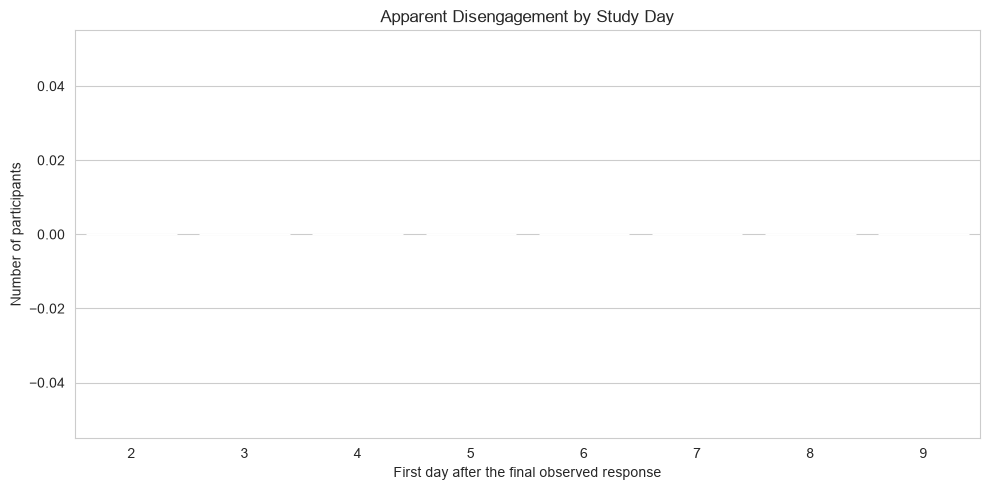

Total participants: 70
Retained through final study day: 70
Apparent disengagement: 0
Never responded: 0


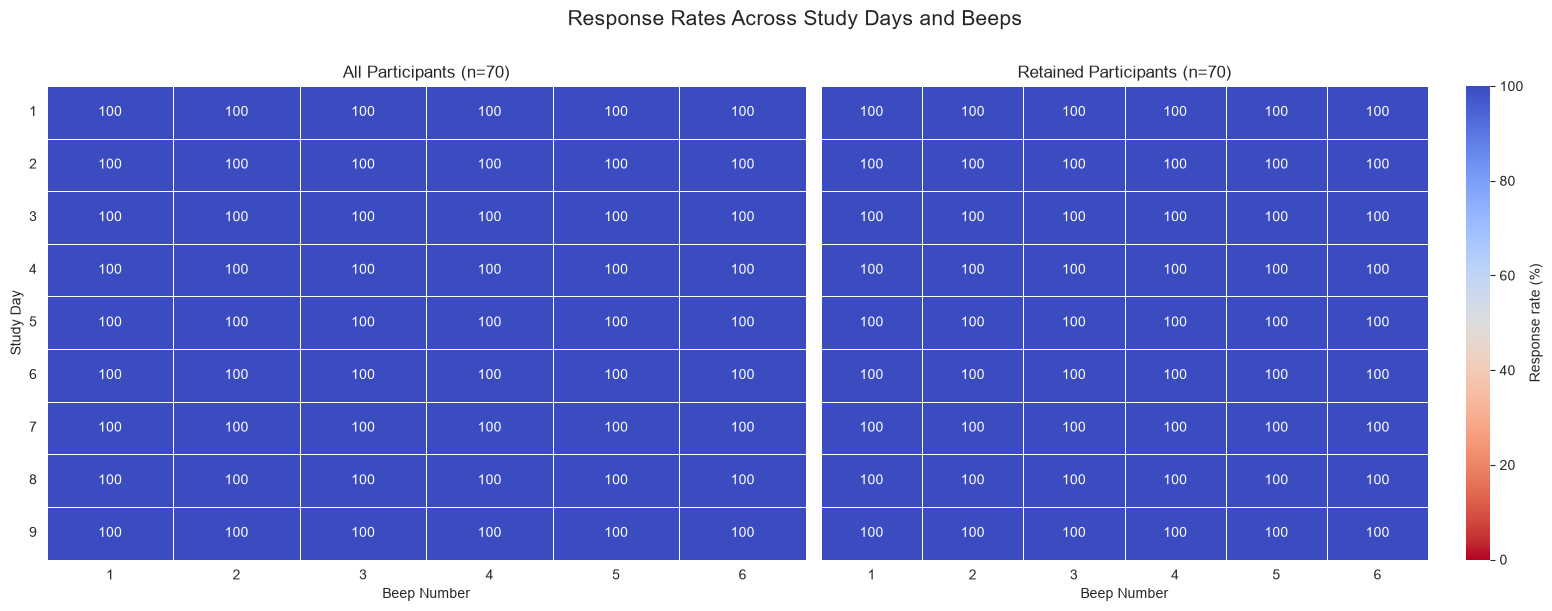

In [ ]:
# Participant Status

participant_status_viz = participant_status.copy()

participant_status_viz["apparent_quit_day"] = (
    participant_status_viz["last_response_day"] + 1
).where(
    participant_status_viz["last_response_day"] < FINAL_STUDY_DAY
)

participant_status_viz["never_responded"] = (
    participant_status_viz["last_response_day"].isna()
)

participant_status_viz["apparent_dropout"] = (
    participant_status_viz["last_response_day"].notna()
    & (
        participant_status_viz["last_response_day"]
        < FINAL_STUDY_DAY
    )
)

participant_status_viz["retained"] = (
    participant_status_viz["last_response_day"]
    == FINAL_STUDY_DAY
)


# Participant Summary

display(
    participant_status_viz.sort_values(
        ["apparent_dropout", "last_response_day"],
        ascending=[False, True],
        na_position="first",
    )
)


# Dropout Distribution

dropout_counts = (
    participant_status_viz[
        participant_status_viz["apparent_dropout"]
    ]
    .groupby("apparent_quit_day")
    .size()
    .reindex(
        range(
            min(EXPECTED_DAYS) + 1,
            FINAL_STUDY_DAY + 1,
        ),
        fill_value=0,
    )
    .rename("participants")
    .reset_index()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=dropout_counts,
    x="apparent_quit_day",
    y="participants",
)

plt.xlabel("First day after the final observed response")
plt.ylabel("Number of participants")
plt.title("Apparent Disengagement by Study Day")

plt.tight_layout()
plt.show()


# Participant Summary Counts

print(f"Total participants: {len(participant_status_viz):,}")

print(
    f"Retained through final study day: "
    f"{participant_status_viz['retained'].sum():,}"
)

print(
    f"Apparent disengagement: "
    f"{participant_status_viz['apparent_dropout'].sum():,}"
)

print(
    f"Never responded: "
    f"{participant_status_viz['never_responded'].sum():,}"
)


# Participant Groups

retained_ids = participant_status_viz.loc[
    participant_status_viz["retained"],
    "id",
]

retained_df = model_df[
    model_df["id"].isin(retained_ids)
].copy()


# Expected Schedule

# Aggregate duplicate participant/day/beep combinations.
# A combination counts as answered if any record indicates a response.

response_data = (
    model_df
    .groupby(
        ["id", "day", "beep"],
        as_index=False,
    )["responded"]
    .max()
)


# Build the Complete Expected Schedule

# Use the participant roster as the denominator.
# This ensures missing schedule combinations count as nonresponses.

participant_ids = (
    participant_status_viz["id"]
    .dropna()
    .unique()
)

expected_schedule = pd.MultiIndex.from_product(
    [
        participant_ids,
        EXPECTED_DAYS,
        EXPECTED_BEEPS,
    ],
    names=["id", "day", "beep"],
).to_frame(index=False)

response_data = expected_schedule.merge(
    response_data,
    on=["id", "day", "beep"],
    how="left",
)

response_data["responded"] = (
    response_data["responded"]
    .fillna(False)
    .astype(bool)
)


# Overall Response Rates

overall_rates = (
    response_data
    .groupby(["day", "beep"])["responded"]
    .mean()
    .mul(100)
    .unstack("beep")
    .reindex(
        index=EXPECTED_DAYS,
        columns=EXPECTED_BEEPS,
    )
)


# Retained Participant Response Rates

retained_rates = (
    response_data[
        response_data["id"].isin(retained_ids)
    ]
    .groupby(["day", "beep"])["responded"]
    .mean()
    .mul(100)
    .unstack("beep")
    .reindex(
        index=EXPECTED_DAYS,
        columns=EXPECTED_BEEPS,
    )
)


# Heatmap Visualization

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, max(6, len(EXPECTED_DAYS) * 0.25)),
    sharey=True,
)

annotate = len(EXPECTED_DAYS) <= 20

sns.heatmap(
    overall_rates,
    ax=axes[0],
    annot=annotate,
    fmt=".0f",
    cmap="coolwarm_r",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar=False,
)

sns.heatmap(
    retained_rates,
    ax=axes[1],
    annot=annotate,
    fmt=".0f",
    cmap="coolwarm_r",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar=True,
    cbar_kws={"label": "Response rate (%)"},
)

axes[0].set_title(
    f"All Participants (n={len(participant_ids)})"
)

axes[1].set_title(
    f"Retained Participants (n={len(retained_ids)})"
)

for ax in axes:
    ax.set_xlabel("Beep Number")
    ax.set_xticklabels(EXPECTED_BEEPS)

    ax.set_yticklabels(
        EXPECTED_DAYS,
        rotation=0,
    )

axes[0].set_ylabel("Study Day")
axes[1].set_ylabel("")

fig.suptitle(
    "Response Rates Across Study Days and Beeps",
    fontsize=15,
    y=1.01,
)

plt.tight_layout()
plt.show()
